In [7]:
import numpy as np

def in_circle(coord, k):
    x, y, z = coord
    return x**2 + y**2 + z**2 <= k**2

def in_torus(coord, R, r, offset=(0, 0, 0)):
    x, y, z = coord
    xc, yc, zc = offset
    return (np.sqrt((x-xc)**2 + (y-yc)**2) - R)**2 + (z-zc)**2 <= r**2


def estimate_monte_carlo(k, R, r, n, sample_method='uniform', offset=(0, 0, 0), log=False, seed=42):
    bbox_size = 2 * (R + r)
    np.random.seed(seed)
    res = []

    match sample_method:
        case 'uniform':
            samples = np.random.uniform(-bbox_size / 2, bbox_size / 2, size=(n, 3))
        case 'logmap':
            logmap = lambda x: 3.8 * x * (1 - x)
            samples = list(np.random.uniform(0, 1, size=(1, 3)))
            for _ in range(n - 1):
                x, y, z = samples[-1]
                x_new = logmap(x)
                y_new = logmap(y)
                z_new = logmap(z)
                samples.append([x_new, y_new, z_new])
            samples = np.array(samples)
        case _:
            raise ValueError("Unsupported sampling method")
    count = 0
    for sample in samples:
        if in_circle(sample, k) and in_torus(sample, R, r, offset):
            count += 1
            if log: res.append(count)
        elif log: res.append(count)

    return count / n * bbox_size**3, np.array(res)

def estimate_monte_carlo_explicit_samples(k, R, r, samples, bbox_volume, offset=(0, 0, 0), log=False, seed=42):
    np.random.seed(seed)
    res = []

    count = 0
    for sample in samples:
        if in_circle(sample, k) and in_torus(sample, R, r, offset):
            count += 1
            if log: res.append(count)
        elif log: res.append(count)

    return count / len(samples) * bbox_volume, np.array(res)

In [8]:
n = 100_000

# case 1
k = 1
R = .75
r = .4

area_estimate, _ = estimate_monte_carlo(k, R, r, n, sample_method='uniform')
print(area_estimate)

1.8424488099999998


In [9]:
# case 2
k = 1
R = .5
r = .5

area_estimate, _ = estimate_monte_carlo(k, R, r, n, sample_method='uniform')
print(area_estimate)

2.46888


In [10]:
k = 1
R = .75
r = .4
offset = (0., 0., 0.1)

area_estimate, _ = estimate_monte_carlo(k, R, r, n, sample_method='uniform', offset=offset)
print(area_estimate)

1.8257800199999996


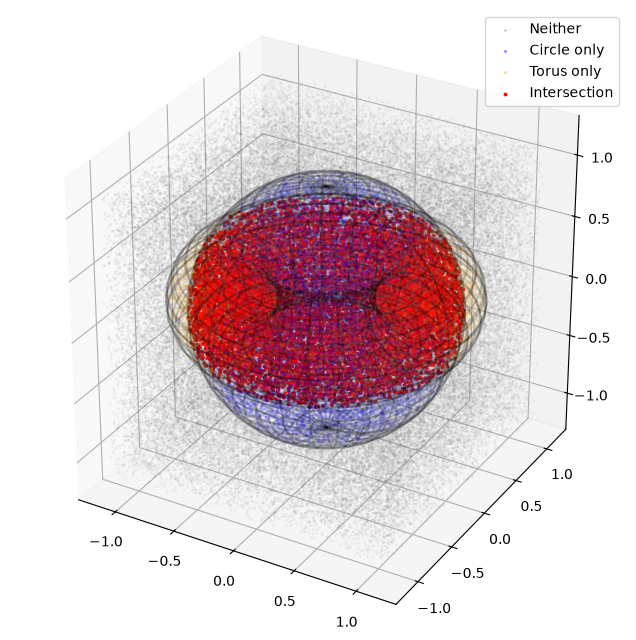

In [11]:
import matplotlib.pyplot as plt

def visualize_system(samples, k, R, r, offset=(0, 0, 0)):
    x0, y0, z0 = offset
    circle = np.sum(samples**2, axis=1) <= k**2
    torus = (np.hypot(samples[:, 0] - x0, samples[:, 1] - y0) - R)**2 + (samples[:, 2] - z0)**2 <= r**2

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")
    u, v = np.meshgrid(np.linspace(0, 2*np.pi, 60), np.linspace(0, np.pi, 30))

    ax.plot_wireframe(k*np.sin(v)*np.cos(u), k*np.sin(v)*np.sin(u), k*np.cos(v), color="black", alpha=0.2)
    v = np.linspace(0, 2*np.pi, 30)[:, None]
    ax.plot_wireframe(x0 + (R+r*np.cos(v))*np.cos(u), y0 + (R+r*np.cos(v))*np.sin(u), z0 + r*np.sin(v)*np.ones_like(u), color="black", alpha=0.2)

    # half = R + r
    # X, Y = np.meshgrid([-half, half], [-half, half])
    # for sign in (-1, 1):
    #     ax.plot_wireframe(X, Y, np.full_like(X, sign * half), color="black", alpha=0.2)
    #     ax.plot_wireframe(X, np.full_like(X, sign * half), Y, color="black", alpha=0.2)
    #     ax.plot_wireframe(np.full_like(X, sign * half), X, Y, color="black", alpha=0.2)

    for  mask,             alpha, size, color, label in [
        (~circle & ~torus, 0.3,   1, "gray", "Neither"),
        (circle & ~torus,  0.3,   2, "blue", "Circle only"),
        (~circle & torus,  0.3,   2, "orange", "Torus only"),
        (circle & torus,   1.0,   3, "red", "Intersection"),
    ]:
        ax.scatter(*samples[mask].T, alpha=alpha, s=size, c=color, label=label)

    ax.set_box_aspect((1, 1, 1))
    ax.legend()
    plt.show()

np.random.seed(42)
samples = np.random.uniform(-R-r, R+r, (n, 3))
visualize_system(samples, k, R, r, offset)

In [12]:
n = 10000
k = 1
R = .75
r = .4

area_estimate, data = estimate_monte_carlo(k, R, r, n, sample_method='uniform', log=True, seed=2)
print(data.shape)

(10000,)


1.8433004999999996


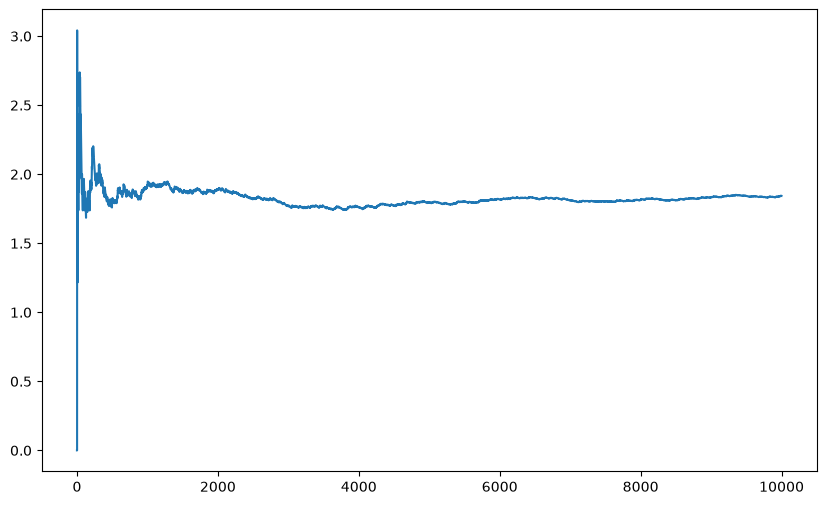

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
bbox_size = 2 * (R + r)
normalized_data = data / (np.arange(data.shape[0])+1) * bbox_size**3
print(area_estimate)

# print((np.arange(data.shape[0])+1)[:10])

ax.plot(normalized_data)

plt.show()

(5, 10000)


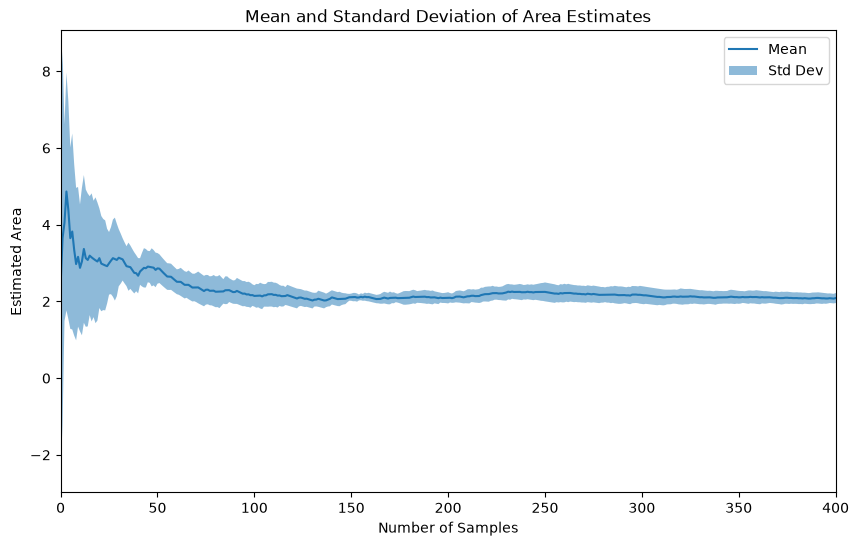

In [14]:
n_runs = 5
runs = np.zeros(shape=(n_runs,n))

def visualize_standard_deviation(runs, bbox_volume, x_lim=None, y_lim=None):
    print(runs.shape)
    std_dev = np.std(runs, axis=0)
    mean = np.mean(runs, axis=0)
    normalized_std_dev = std_dev / (np.arange(runs.shape[1])+1) * bbox_volume
    normalized_mean = mean / (np.arange(runs.shape[1])+1) * bbox_volume

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    ax.plot(normalized_mean, label='Mean')
    ax.fill_between(np.arange(runs.shape[1]), normalized_mean - normalized_std_dev, normalized_mean + normalized_std_dev, alpha=0.5, label='Std Dev')
    ax.set_title('Mean and Standard Deviation of Area Estimates')
    ax.set_xlabel('Number of Samples')
    ax.set_ylabel('Estimated Area')
    ax.legend()
    if x_lim is not None:
        ax.set_xlim(x_lim)
    if y_lim is not None:
        ax.set_ylim(y_lim)
    return ax

for i, seed in enumerate(range(1000, 1000 + n_runs)):
    area_estimate, data = estimate_monte_carlo(k, R, r, n, sample_method='uniform', log=True, seed=seed)
    runs[i] = data


visualize_standard_deviation(runs, bbox_size**3, x_lim=(0, 400))
    
plt.show()

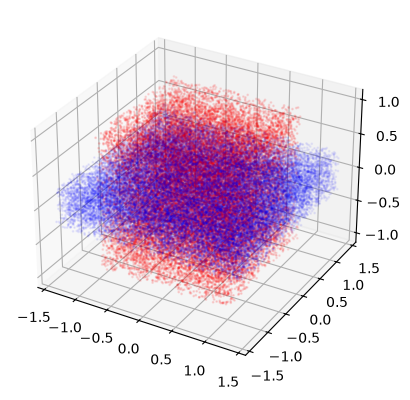

In [15]:
n = 30000
k = 1
R = 1.1
r = .3


bbox_circle_radius = k
bbox_torus_width = 2 * (R + r)
bbox_torus_height = 2 * r

samples_circle = np.random.uniform(-bbox_circle_radius, bbox_circle_radius, size=(n, 3))

samples_torus = np.hstack((np.random.uniform(-bbox_torus_width / 2, bbox_torus_width / 2, size=(n, 2)), np.random.uniform(-bbox_torus_height / 2, bbox_torus_height / 2, size=(n, 1))))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(samples_torus[:, 0], samples_torus[:, 1], samples_torus[:, 2], s=1, alpha=0.3, c='blue', label='Torus Samples')
ax.scatter(samples_circle[:, 0], samples_circle[:, 1], samples_circle[:, 2], s=1, alpha=0.4, c='red', label='Circle Samples')


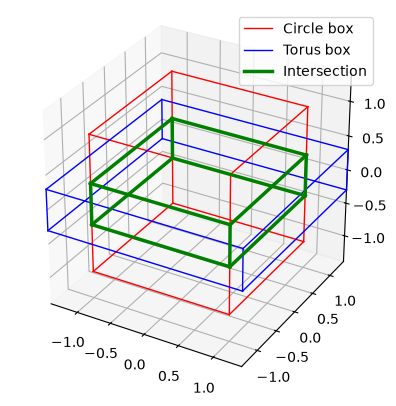

In [16]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection="3d")

for width, height, color, label, line_width in [
    (2 * bbox_circle_radius, 2 * bbox_circle_radius, "red", "Circle box", 1),
    (bbox_torus_width, bbox_torus_height, "blue", "Torus box", 1),
    (2 * min(bbox_circle_radius, bbox_torus_width / 2), 2 * min(bbox_circle_radius, bbox_torus_height / 2), "green", "Intersection", 2.5),
]:
    w, h = width / 2, height / 2
    first = True
    for x in (-w, w):
        for y in (-w, w):
            ax.plot([x, x], [y, y], [-h, h], color=color, linewidth=line_width, label=label if first else "_nolegend_")
            first = False
        for z in (-h, h):
            ax.plot([x, x], [-w, w], [z, z], color=color, linewidth=line_width)
    for y in (-w, w):
        for z in (-h, h):
            ax.plot([-w, w], [y, y], [z, z], color=color, linewidth=line_width)

limit = max(bbox_circle_radius, bbox_torus_width / 2)
ax.set(xlim=(-limit, limit), ylim=(-limit, limit), zlim=(-limit, limit))
ax.set_box_aspect((1, 1, 1))
ax.legend()
plt.show()

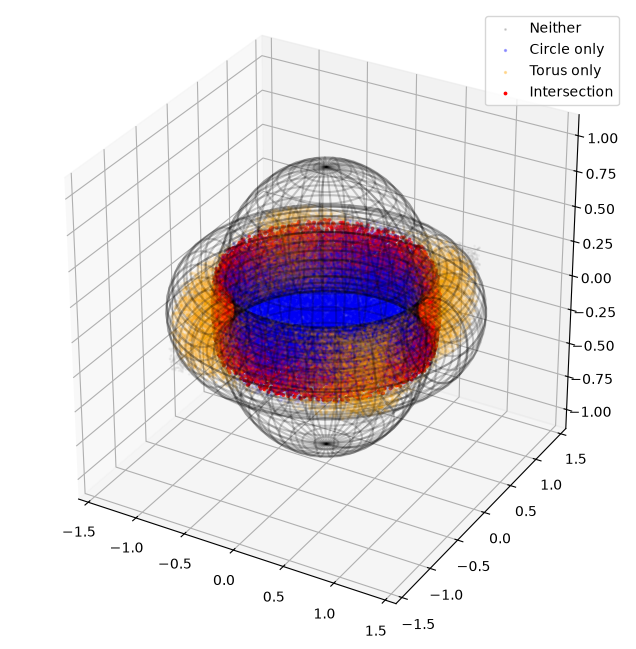

In [17]:

bbox_optimal_height = np.min([k, r])
bbox_optimal_width = np.min([k, R + r])

n = 100000
samples = np.hstack((
    np.random.uniform(-bbox_optimal_width, bbox_optimal_width, size=(n, 2)),
    np.random.uniform(-bbox_optimal_height, bbox_optimal_height, size=(n, 1))
))


visualize_system(samples, k, R, r, offset=(0, 0, 0))


(5, 100000, 3)
(5, 100000)
(5, 10000)


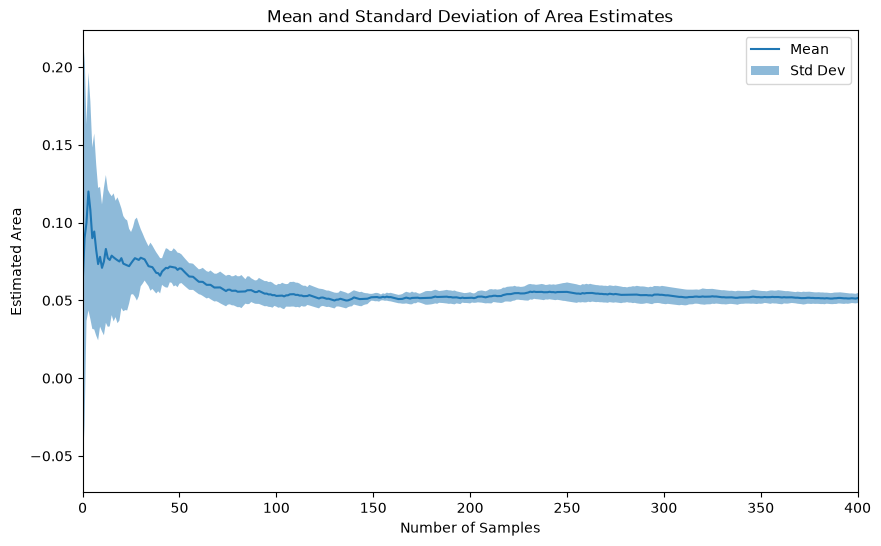

In [18]:
n = 100_000
all_samples = np.zeros((n_runs, n, 3))
print(all_samples.shape)

for i in range(n_runs):
    all_samples[i] = np.hstack((
        np.random.uniform(-bbox_optimal_width, bbox_optimal_width, size=(n, 2)),
        np.random.uniform(-bbox_optimal_height, bbox_optimal_height, size=(n, 1))
    ))

bbox_volume = bbox_optimal_width**2 * bbox_optimal_height

# test_run, test = estimate_monte_carlo_explicit_samples(k, R, r, samples, bbox_optimal_width**2 * bbox_optimal_height, log=True, seed=42)
# print(test.shape)
data = np.array([estimate_monte_carlo_explicit_samples(k, R, r, samples, bbox_volume, log=True, seed=42)[1] for samples in all_samples])
print(data.shape)
# break

visualize_standard_deviation(runs, bbox_optimal_width**2 * bbox_optimal_height, x_lim=(0, 400))
plt.show()

In [19]:
all_samples

array([[[-5.09323000e-01, -6.50232555e-01, -1.73424219e-01],
        [ 2.09189412e-01,  1.16848257e-01, -1.95309608e-01],
        [-3.12745222e-01,  9.24562595e-01,  1.11229172e-01],
        ...,
        [-5.81286111e-01, -3.13436776e-01,  2.55341220e-01],
        [ 8.66135569e-01, -7.35971505e-01, -4.93041659e-03],
        [-1.98036818e-01,  7.98858349e-01, -1.85958334e-01]],

       [[-2.05876498e-01, -8.35678958e-01, -2.37934226e-01],
        [ 8.00575572e-01, -3.55469120e-01,  1.21787749e-01],
        [ 1.81863995e-01, -3.82433820e-01,  1.95457642e-02],
        ...,
        [ 1.23304713e-02,  1.23255123e-01,  1.94713425e-01],
        [-6.20368077e-01, -3.17585343e-01, -2.30479866e-01],
        [-8.09246790e-01,  3.06862513e-01, -7.98054781e-02]],

       [[ 3.74212959e-01, -2.32224702e-01, -1.55038562e-01],
        [ 8.83102216e-02,  6.65050511e-01, -8.94779663e-02],
        [-2.16276686e-01,  3.96509917e-01, -3.35815824e-02],
        ...,
        [ 8.20041407e-01,  7.40417332e-01,

In [37]:
import os, shutil
import tempfile
from itertools import product

In [38]:
k, R, r = 1.0, 0.75, 0.4
offset = (0.0, 0.0, 0.1)

N_BIG = 100_000     
N_CONV = 10_000     
N_RUNS = 5

In [39]:
def in_sphere(p, k):
    return np.sum(p**2, axis=1) <= k**2

def in_torus(p, R, r, offset=(0, 0, 0)):
    xc, yc, zc = offset
    return (np.hypot(p[:, 0] - xc, p[:, 1] - yc) - R)**2 + (p[:, 2] - zc)**2 <= r**2

def running_estimate(p, k, R, r, V, offset=(0, 0, 0)):
    hit = in_sphere(p, k) & in_torus(p, R, r, offset)
    return np.cumsum(hit) / np.arange(1, len(p) + 1) * V

def sample_box(n, half_xy, half_z, seed):
    rng = np.random.default_rng(seed)
    return np.column_stack((rng.uniform(-half_xy, half_xy, (n, 2)), rng.uniform(-half_z, half_z, (n, 1))))

def save(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [40]:
def scatter_system(samples, k, R, r, offset, title):
    x0, y0, z0 = offset
    sph = in_sphere(samples, k)
    tor = in_torus(samples, R, r, offset)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")
    u, v = np.meshgrid(np.linspace(0, 2*np.pi, 60), np.linspace(0, np.pi, 30))
    ax.plot_wireframe(k*np.sin(v)*np.cos(u), k*np.sin(v)*np.sin(u), k*np.cos(v),
                      color="black", alpha=0.2)
    v = np.linspace(0, 2*np.pi, 30)[:, None]
    ax.plot_wireframe(x0 + (R + r*np.cos(v))*np.cos(u),
                      y0 + (R + r*np.cos(v))*np.sin(u),
                      z0 + r*np.sin(v)*np.ones_like(u), color="black", alpha=0.2)
    for mask, alpha, size, color, label in [
        (~sph & ~tor, 0.3, 1, "gray",   "Neither"),
        (sph & ~tor,  0.3, 2, "blue",   "Sphere only"),
        (~sph & tor,  0.3, 2, "orange", "Torus only"),
        (sph & tor,   1.0, 3, "red",    "Intersection"),
    ]:
        ax.scatter(*samples[mask].T, alpha=alpha, s=size, c=color, label=label)
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(title)
    ax.legend()
    return fig

def draw_box(ax, half_xy, half_z, color, label, lw=1):
    corners = np.array(list(product([-half_xy, half_xy], [-half_xy, half_xy], [-half_z, half_z])))
    first = True
    for a in range(8):
        for b in range(a + 1, 8):
            if np.sum(corners[a] != corners[b]) == 1:      # edge = corners differing in one axis
                ax.plot(*zip(corners[a], corners[b]), color=color, linewidth=lw,
                        label=label if first else "_nolegend_")
                first = False

def mean_std_plot(runs_est, title, xlim=None):
    mean, std = runs_est.mean(axis=0), runs_est.std(axis=0)
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(runs_est.shape[1])
    ax.plot(mean, label="Mean")
    ax.fill_between(x, mean - std, mean + std, alpha=0.5, label="Std Dev")
    ax.set_title(title)
    ax.set_xlabel("Number of Samples")
    ax.set_ylabel("Estimated Volume")
    ax.legend()
    if xlim is not None:
        ax.set_xlim(xlim)
    return fig

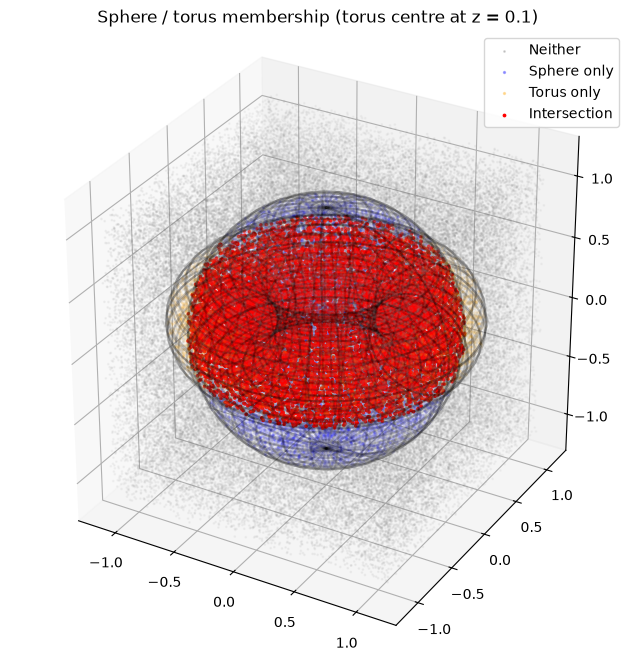

In [41]:
half = R + r
samples = sample_box(N_BIG, half, half, seed=42)
fig = scatter_system(samples, k, R, r, offset, "Sphere / torus membership (torus centre at z = 0.1)")
save(fig, "fig1_scatter_offset_torus")

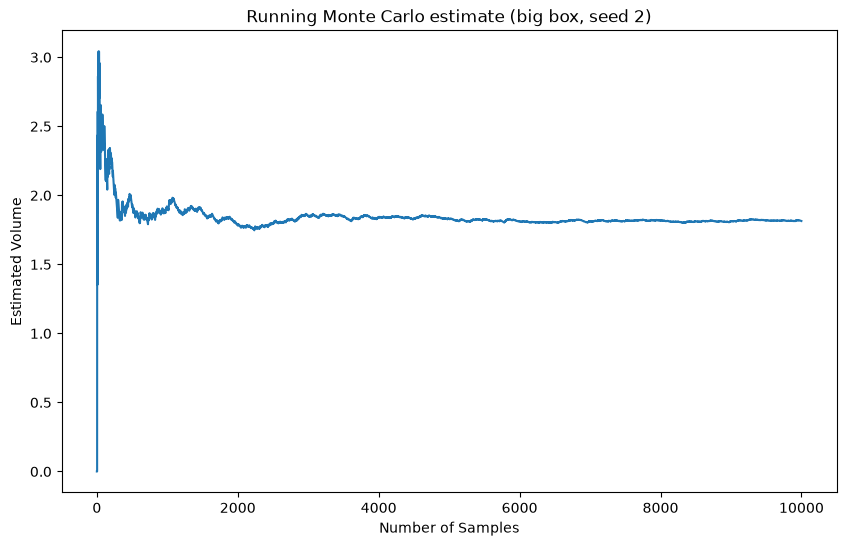

In [42]:
V_big = (2 * (R + r))**3
p = sample_box(N_CONV, half, half, seed=2)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(running_estimate(p, k, R, r, V_big))
ax.set_title("Running Monte Carlo estimate (big box, seed 2)")
ax.set_xlabel("Number of Samples"); ax.set_ylabel("Estimated Volume")
save(fig, "fig2_running_estimate")

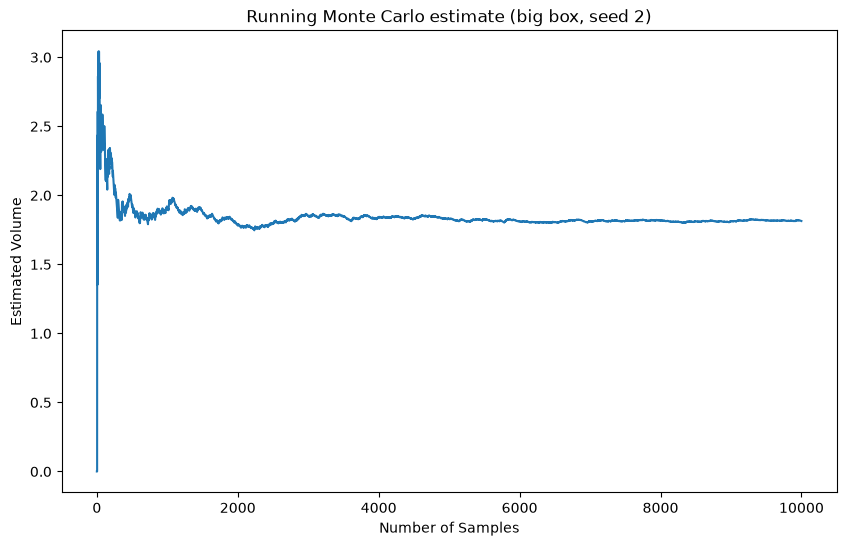

In [43]:
V_big = (2 * (R + r))**3
p = sample_box(N_CONV, half, half, seed=2)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(running_estimate(p, k, R, r, V_big))
ax.set_title("Running Monte Carlo estimate (big box, seed 2)")
ax.set_xlabel("Number of Samples"); ax.set_ylabel("Estimated Volume")
save(fig, "fig2_running_estimate")

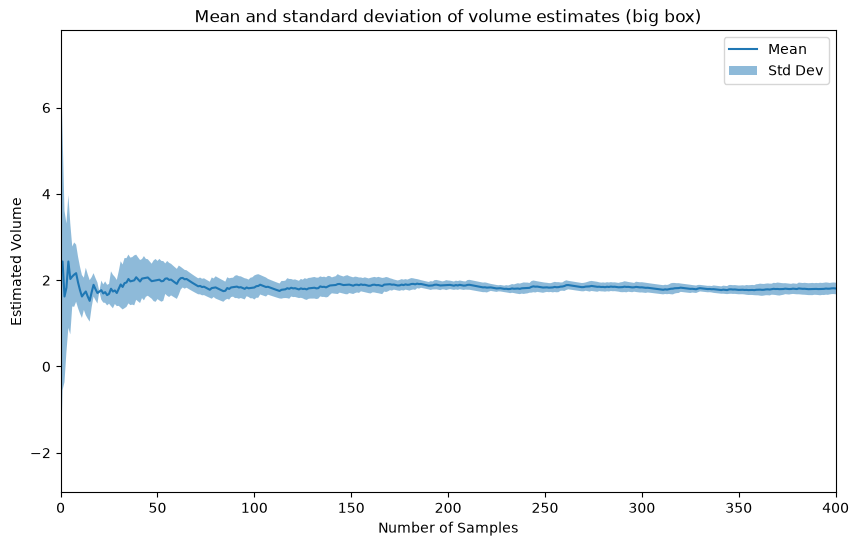

In [44]:
runs = np.array([running_estimate(sample_box(N_CONV, half, half, seed=s), k, R, r, V_big)
                 for s in range(1000, 1000 + N_RUNS)])
fig = mean_std_plot(runs, "Mean and standard deviation of volume estimates (big box)", xlim=(0, 400))
save(fig, "fig3_mean_std_big_box")

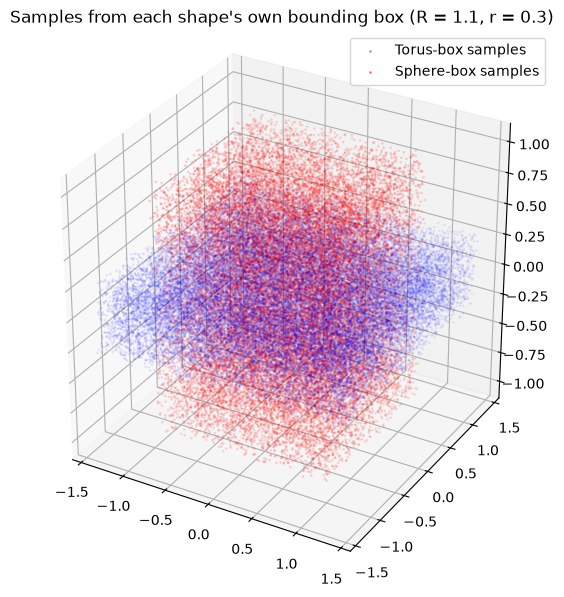

In [45]:
R2, r2, n2 = 1.1, 0.3, 30_000
rng = np.random.default_rng(0)
s_sph = rng.uniform(-k, k, (n2, 3))
s_tor = np.column_stack((rng.uniform(-(R2 + r2), R2 + r2, (n2, 2)), rng.uniform(-r2, r2, (n2, 1))))
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(*s_tor.T, s=1, alpha=0.3, c="blue", label="Torus-box samples")
ax.scatter(*s_sph.T, s=1, alpha=0.4, c="red", label="Sphere-box samples")
ax.set_box_aspect((1, 1, 1)); ax.set_title("Samples from each shape's own bounding box (R = 1.1, r = 0.3)")
ax.legend()
save(fig, "fig4_samples_per_bounding_box")

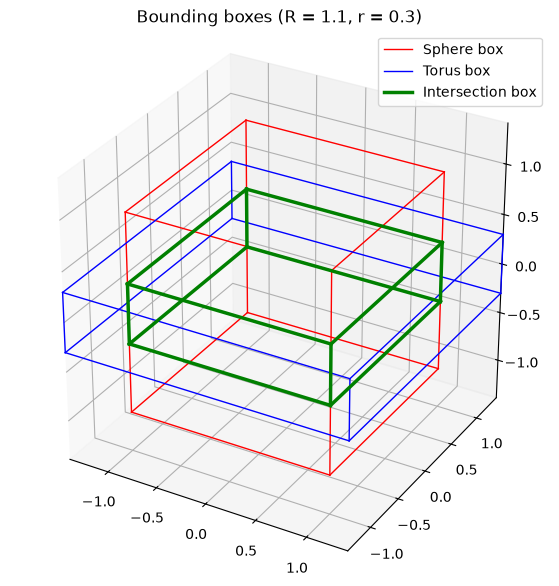

In [46]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
draw_box(ax, k, k, "red", "Sphere box")
draw_box(ax, R2 + r2, r2, "blue", "Torus box")
draw_box(ax, min(k, R2 + r2), min(k, r2), "green", "Intersection box", lw=2.5)
lim = max(k, R2 + r2)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim))
ax.set_box_aspect((1, 1, 1)); ax.set_title("Bounding boxes (R = 1.1, r = 0.3)")
ax.legend()
save(fig, "fig5_bounding_boxes")

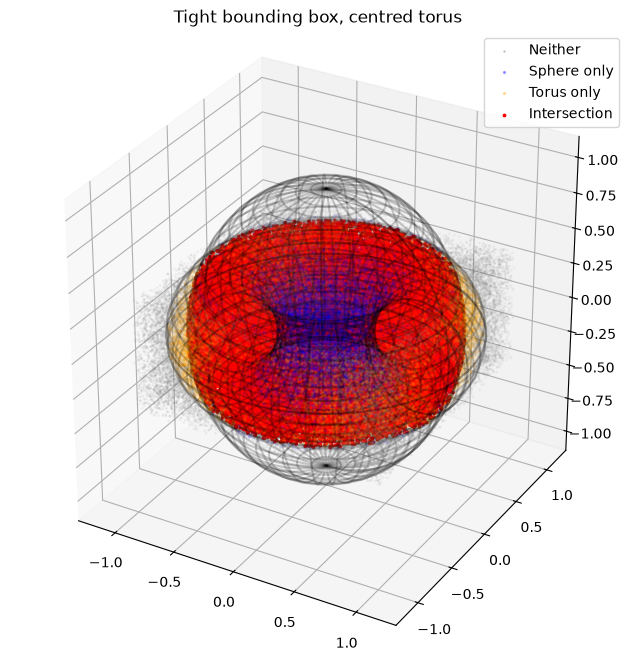

In [47]:
hw, hh = min(k, R + r), min(k, r)          # half-width, half-height
V_tight = (2 * hw)**2 * (2 * hh)           # full box volume = 8 * hw^2 * hh
samples_t = sample_box(N_BIG, hw, hh, seed=42)
fig = scatter_system(samples_t, k, R, r, (0, 0, 0), "Tight bounding box, centred torus")
save(fig, "fig6_scatter_tight_box")

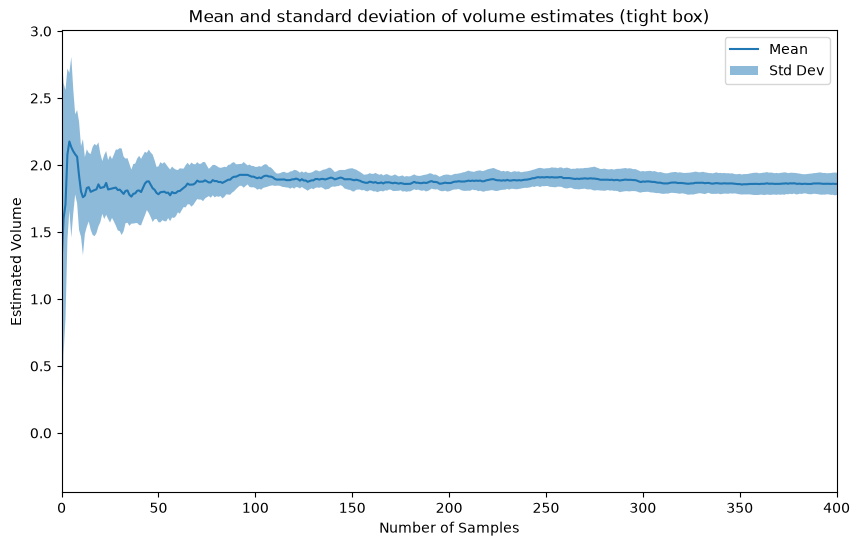

In [48]:
runs_t = np.array([running_estimate(sample_box(N_BIG, hw, hh, seed=s), k, R, r, V_tight)
                   for s in range(1000, 1000 + N_RUNS)])
fig = mean_std_plot(runs_t, "Mean and standard deviation of volume estimates (tight box)", xlim=(0, 400))
save(fig, "fig7_mean_std_tight_box")

In [50]:
zip_path = shutil.make_archive(
    os.path.join(tempfile.gettempdir(), "stochastic_figures"),
    "zip",
    OUT,
)
try:
    from google.colab import files           # Google Colab
    files.download(zip_path)
except ImportError:
    import base64
    from IPython.display import HTML, display

    with open(zip_path, "rb") as zip_file:
        zip_data = base64.b64encode(zip_file.read()).decode("ascii")
    os.remove(zip_path)
    display(HTML(
        f'<a download="stochastic_figures.zip" href="data:application/zip;base64,{zip_data}">'
        'Download stochastic_figures.zip</a>'
    ))